<a href="https://colab.research.google.com/github/aregueiraaraujo/Data-Analytics/blob/main/Sprint%209/Sprint_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#NIVEL 1

In [ ]:
pip install streamlit

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import streamlit as st
import plotly.express as px

Algoritmo
- Importar las tablas csv. del ejercício 8 del sprint 2;

In [29]:
# Importación de la base de datos de transacciones.
transactions = pd.read_csv("/content/N1-Ex.8__transactions.csv", sep=";")

# Importación de la base de datos de productos.
productos = pd.read_csv("/content/N1-Ex.8__products.csv")

# Importación de la base de datos de european users.
EU_users = pd.read_csv("/content/N1-Ex.8__european_users.csv")

# Importación de la base de datos de american users.
EUA_users = pd.read_csv("/content/N1-Ex.8__american_users.csv")

# Importación de la base de datos de credit cards.
credit_cards = pd.read_csv("/content/N1-Ex.8__credit_cards.csv")

# Importación de la base de datos de companies.
companies = pd.read_csv("/content/N1-Ex.8__companies.csv")

Ejercicio 1: Preguntas analíticas directas (sin integraciones complejas)

Algoritmo:
- Pregunta 1: Agrupar las transacciones por periodo temporal (aquí elegimos el año) y visualizar el resultado en un nuevo dataframe.
- Pregunta 2: Agrupar las transacciones por el ID de cada tarjeta de crédito, determinar qué tarjeta de crédito registró la mayor cantidad de ventas, identificar al usuario propietario de dicha tarjeta y verificar si cada usuario posee más de una tarjeta.
- Pregunta 3: Extraer de la tabla el promedio de los valores de las compras por día de la semana y representarlo en un gráfico de barras.

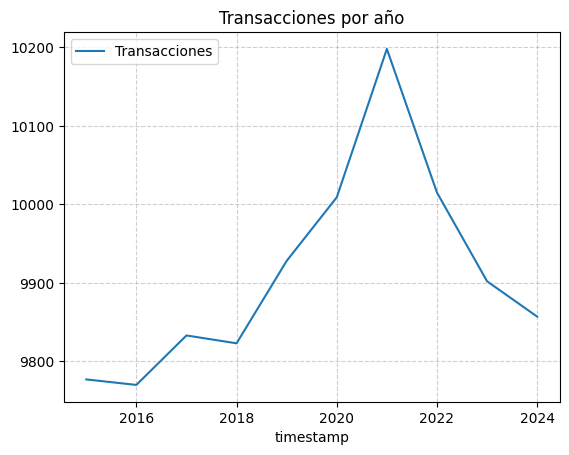

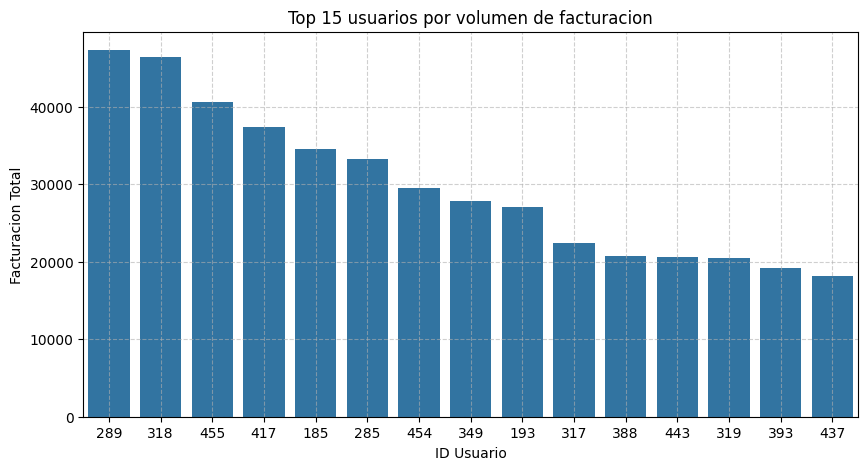

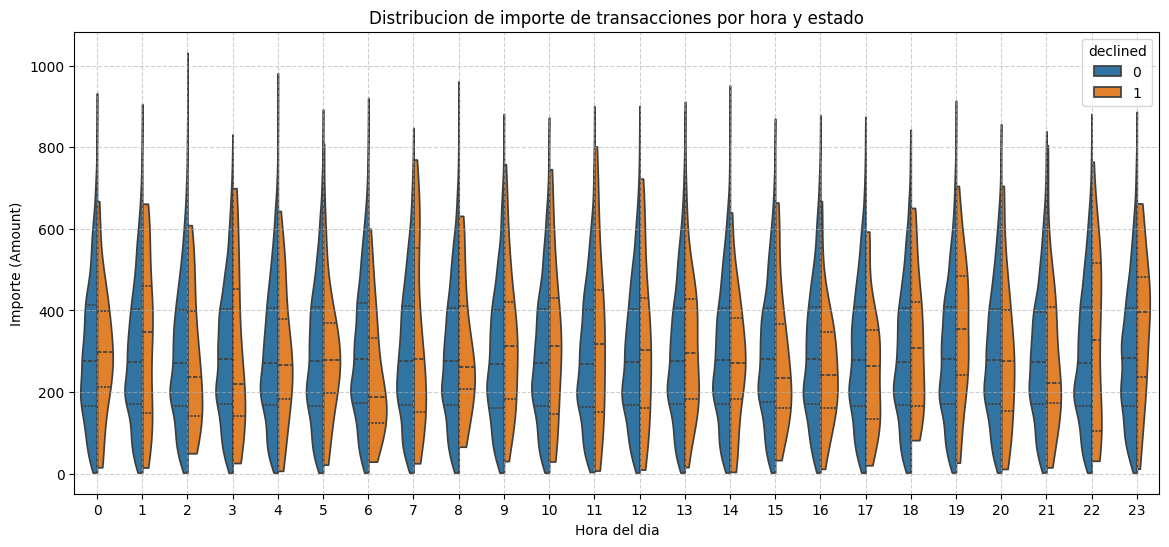

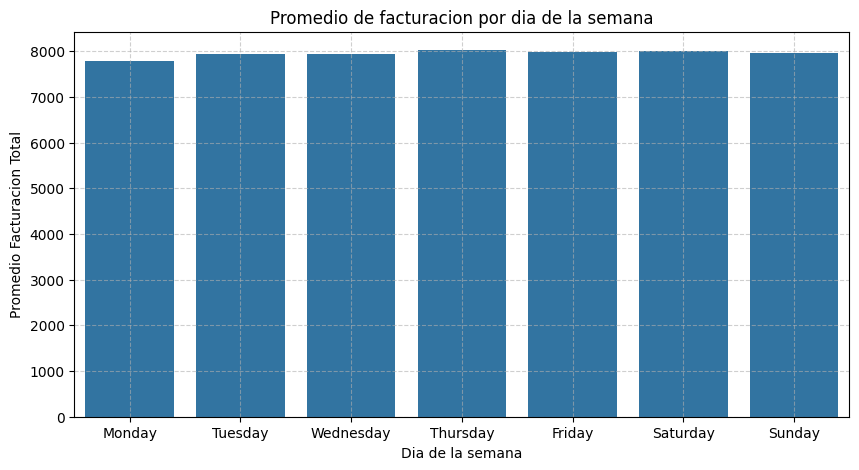

In [31]:
# Codigo sin IA

def transacciones_por_tiempo(df):

  df_tra = df.copy()
  df_tra = df_tra[df_tra["declined"] == 0]
  df_tra = df_tra.sort_values("timestamp")[["timestamp", "id"]]
  df_tra["timestamp"] = pd.to_datetime(df_tra["timestamp"], errors="coerce")

  resultado = df_tra.groupby(df_tra["timestamp"].dt.year)["id"].agg(["count"]).reset_index()
  resultado.rename(columns={"count": "Total"}, inplace=True)

  grafico = resultado.plot(kind='line', x='timestamp', y='Total', title="Transacciones por año", legend=True, label="Transacciones")
  grafico.legend(loc='upper left')
  grafico.grid(True, linestyle='--', alpha=0.6)

  figura_tiempo = grafico.get_figure()
  plt.close(figura_tiempo)

  return resultado, figura_tiempo

def verificar_tarjetas_por_usuario(df):

  df_tra = df.copy()

  conteo = df_tra.groupby("user_id")["card_id"].nunique().reset_index()
  conteo.rename(columns={"card_id": "total_tarjetas"}, inplace=True)

  mas_de_una = conteo[conteo["total_tarjetas"] > 1]

  if len(mas_de_una) > 0:
      print("Se encontraron usuarios con mas de una tarjeta.")
      display(mas_de_una)
  else:
      print("Cada usuario tiene exactamente 1 sola tarjeta de credito.")

  return conteo

def usuario_mayor_facturacion(df, top_n=15):

  df_tra = df.copy()
  df_tra = df_tra[df_tra["declined"] == 0]
  resultado = df_tra.groupby("user_id")["amount"].sum().reset_index()
  resultado.rename(columns={"amount": "Total_Facturacion"}, inplace=True)
  resultado = resultado.sort_values("Total_Facturacion", ascending=False)

  max_facturacion = resultado["Total_Facturacion"].max()
  top_user = resultado[resultado["Total_Facturacion"] == max_facturacion]

  top_plot = resultado.head(top_n).copy()
  top_plot["user_id"] = top_plot["user_id"].astype(str)

  figura_facturacion = plt.figure(figsize=(10, 5))
  sns.barplot(data=top_plot, x="user_id", y="Total_Facturacion")
  plt.title("Top " + str(top_n) + " usuarios por volumen de facturacion")
  plt.xlabel("ID Usuario")
  plt.ylabel("Facturacion Total")
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.close(figura_facturacion)

  return top_user, figura_facturacion

def distribucion_transac(df):

  df_tra = df.copy()
  df_tra["timestamp"] = pd.to_datetime(df_tra["timestamp"], errors="coerce")
  df_tra["hora"] = df_tra["timestamp"].dt.hour

  figura_distribucion = plt.figure(figsize=(14, 6))
  sns.violinplot(data=df_tra,x="hora", y="amount", hue="declined",split=True,inner="quartile",cut=0)
  plt.title("Distribucion de importe de transacciones por hora y estado")
  plt.xlabel("Hora del dia")
  plt.ylabel("Importe (Amount)")
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.close(figura_distribucion)

  return figura_distribucion

def dia_semana_mas_ventas(df):

  df_tra = df. copy()
  df_tra = df_tra[df_tra["declined"] == 0]
  df_tra["timestamp"] = pd.to_datetime(df_tra["timestamp"], errors="coerce")
  df_tra["fecha"] = df_tra["timestamp"].dt.date
  df_tra["dia_semana"] = df_tra["timestamp"].dt.day_name()
  orden_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
  ventas_diarias = df_tra.groupby(["fecha", "dia_semana"])["amount"].sum().reset_index()
  promedio_dia = ventas_diarias.groupby("dia_semana")["amount"].mean().reset_index()
  promedio_dia.rename(columns={"amount": "Promedio_Facturacion"}, inplace=True)

  promedio_dia["dia_semana"] = pd.Categorical(promedio_dia["dia_semana"], categories=orden_dias, ordered=True)
  promedio_dia = promedio_dia.sort_values("dia_semana")

  figura_dia_semana = plt.figure(figsize=(10, 5))
  sns.barplot(data=promedio_dia, x="dia_semana", y="Promedio_Facturacion")
  plt.title("Promedio de facturacion por dia de la semana")
  plt.xlabel("Dia de la semana")
  plt.ylabel("Promedio Facturacion Total")
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.close(figura_dia_semana)

  return promedio_dia, figura_dia_semana

def main_preguntas(Tra):

  t_o_t, fig_tiempo = transacciones_por_tiempo(Tra)
  usr_ventas, fig_facturacion = usuario_mayor_facturacion(Tra)
  fig_dist = distribucion_transac(Tra)
  promedio, fig_fac_dia = dia_semana_mas_ventas(Tra)

  return t_o_t, fig_tiempo, usr_ventas, fig_facturacion, fig_dist, promedio, fig_fac_dia

df_tiempo, graf_tiempo, df_usr_ventas, graf_facturacion, graf_dist,df_promedio, graf_fac_dia = main_preguntas(transactions)

display(graf_tiempo)
display(graf_facturacion)
display(graf_dist)
display(graf_fac_dia)




PREGUNTA 1: ¿Cómo evoluciona el número de transacciones a lo largo del tiempo?


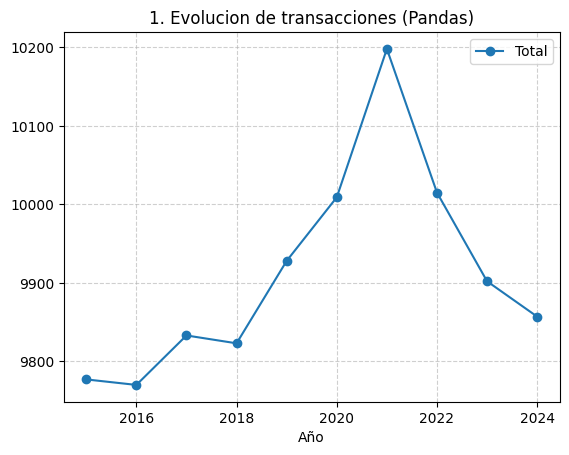

Interpretacion: El grafico de lineas anual identifica visualmente si el negocio esta en fase de crecimiento, estancamiento o declive a nivel operativo.


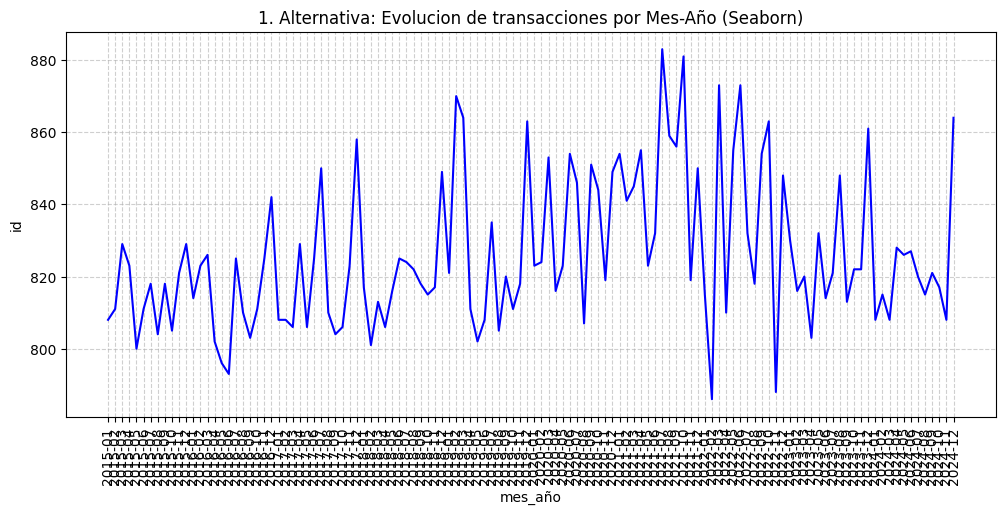

Propuesta IA (Alternativa): Aumentar la granularidad a Mes-Año permite detectar ciclos de estacionalidad intra-anual que el analisis anual oculta.
------------------------------------------------------------------------------------------

PREGUNTA 2: ¿Qué usuarios generan mayor volumen de facturación?


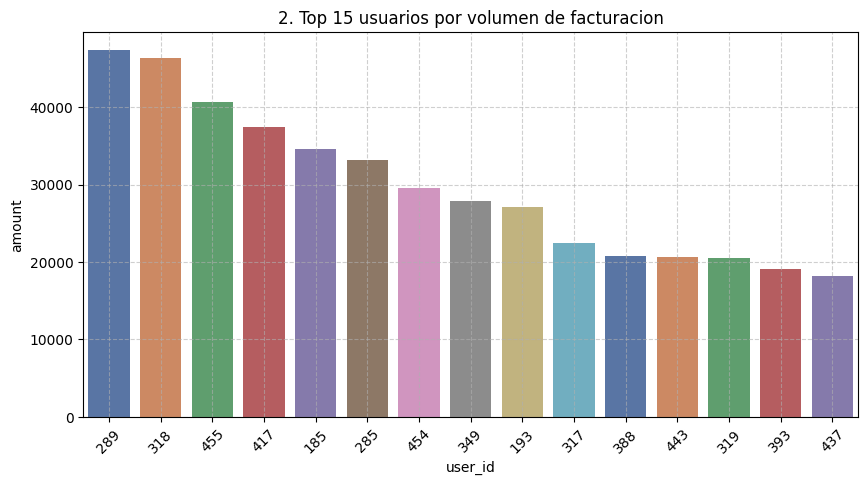

Interpretacion: Identificar de forma rapida a los clientes VIP o cuentas mas valiosas sumando el importe historico de todas sus transacciones aprobadas.


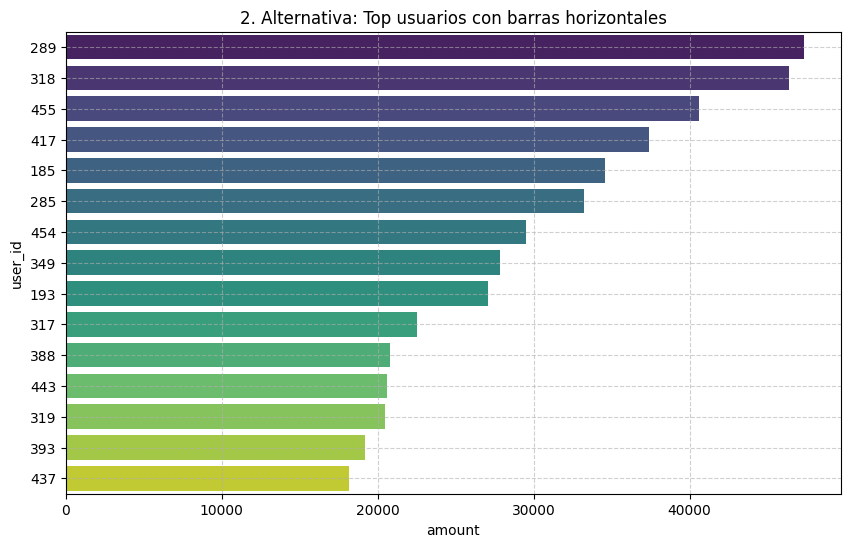

Propuesta IA (Alternativa): Cambiar la orientacion a barras horizontales elimina la necesidad de rotar el texto del eje X, facilitando enormemente la lectura de los IDs.
------------------------------------------------------------------------------------------

PREGUNTA 3: ¿Existen diferencias en la distribución del importe según la hora y si han sido aceptadas o rechazadas?


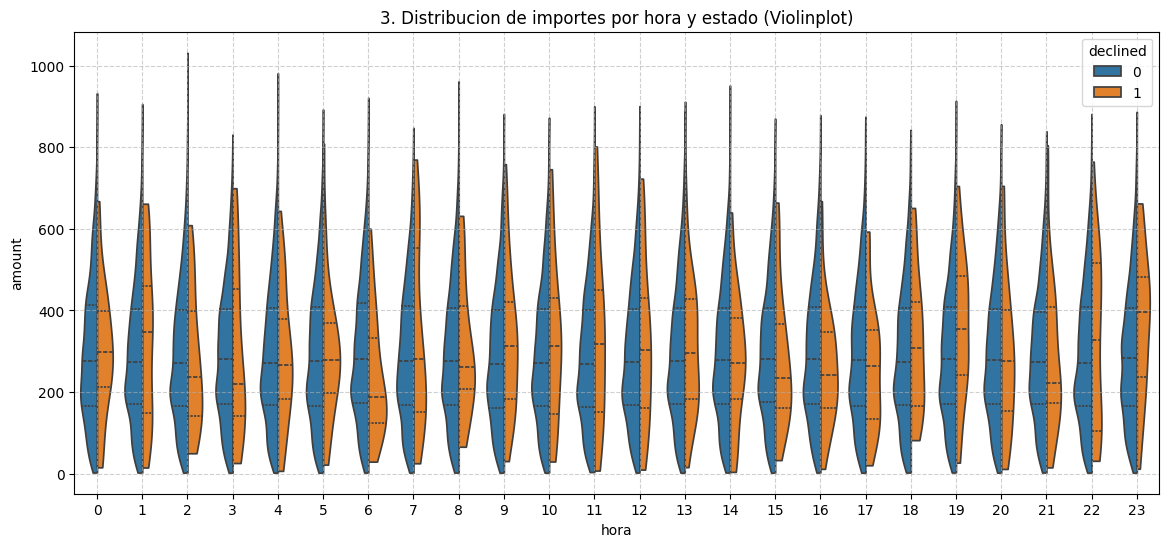

Interpretacion: El violinplot revela en que horarios ocurren transacciones mas altas y compara su densidad para ver si los rechazos (naranja) se concentran en importes sospechosamente elevados.


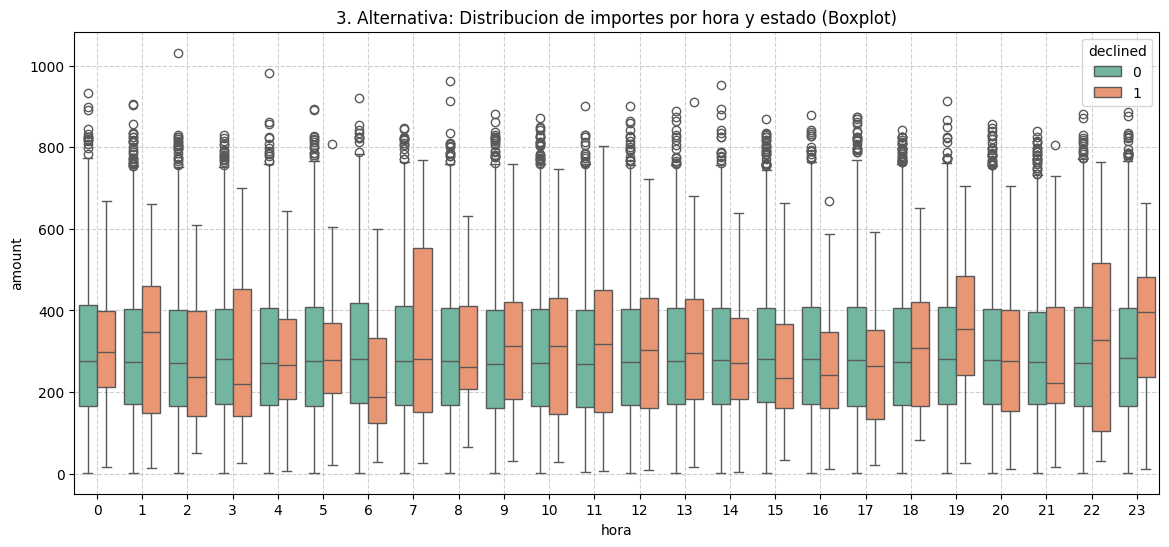

Propuesta IA (Alternativa): Reemplazar el violinplot por un boxplot incrementa drasticamente el rendimiento en grandes volumenes de datos y visibiliza mejor los valores atipicos (outliers).
------------------------------------------------------------------------------------------

PREGUNTA 4: ¿Qué días de la semana se concentra mayor actividad de venta?


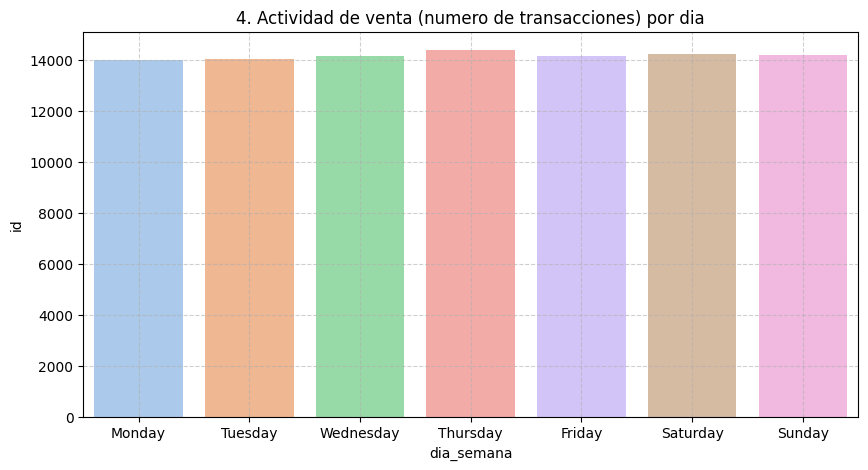

Interpretacion: El grafico de barras por recuento de IDs evidencia claramente los dias de mayor pico operativo para dimensionar necesidades de soporte o infraestructura.


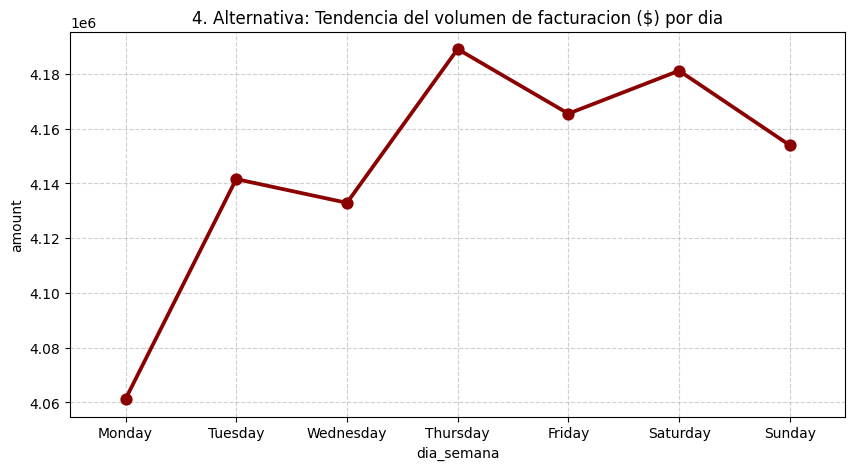

Propuesta IA (Alternativa): En vez de contar transacciones, graficar la tendencia continua del dinero sumado (pointplot) permite descubrir si los dias con menos transacciones generan quizas mas ingresos monetarios.


In [32]:
# Codigo hecho por IA

def q1_base(df):
    df_tra = df[df["declined"] == 0].copy()
    df_tra["timestamp"] = pd.to_datetime(df_tra["timestamp"], errors="coerce")

    resultado = df_tra.groupby(df_tra["timestamp"].dt.year)["id"].count().reset_index()
    resultado.rename(columns={"timestamp": "Año", "id": "Total"}, inplace=True)
    resultado = resultado.sort_values("Año")

    grafico = resultado.plot(kind='line', x='Año', y='Total', title="1. Evolucion de transacciones (Pandas)", marker='o')
    grafico.grid(True, linestyle='--', alpha=0.6)

    fig = grafico.get_figure()
    plt.close(fig)
    return fig

def q1_alt(df):
    df_tra = df[df["declined"] == 0].copy()
    df_tra["timestamp"] = pd.to_datetime(df_tra["timestamp"], errors="coerce")
    df_tra["mes_año"] = df_tra["timestamp"].dt.to_period("M").astype(str)

    resultado = df_tra.groupby("mes_año")["id"].count().reset_index()
    resultado = resultado.sort_values("mes_año")

    fig = plt.figure(figsize=(12, 5))
    sns.lineplot(data=resultado, x="mes_año", y="id", color="blue")
    plt.xticks(rotation=90)
    plt.title("1. Alternativa: Evolucion de transacciones por Mes-Año (Seaborn)")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.close(fig)
    return fig

def q2_base(df, top_n=15):
    df_tra = df[df["declined"] == 0].copy()

    resultado = df_tra.groupby("user_id")["amount"].sum().reset_index()
    resultado = resultado.sort_values("amount", ascending=False).head(top_n)
    resultado["user_id"] = resultado["user_id"].astype(str)

    fig = plt.figure(figsize=(10, 5))
    sns.barplot(data=resultado, x="user_id", y="amount", hue="user_id", palette="deep", legend=False)
    plt.title("2. Top " + str(top_n) + " usuarios por volumen de facturacion")
    plt.xticks(rotation=45)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.close(fig)
    return fig

def q2_alt(df, top_n=15):
    df_tra = df[df["declined"] == 0].copy()

    resultado = df_tra.groupby("user_id")["amount"].sum().reset_index()
    resultado = resultado.sort_values("amount", ascending=False).head(top_n)
    resultado["user_id"] = resultado["user_id"].astype(str)

    fig = plt.figure(figsize=(10, 6))
    sns.barplot(data=resultado, x="amount", y="user_id", hue="user_id", palette="viridis", legend=False)
    plt.title("2. Alternativa: Top usuarios con barras horizontales")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.close(fig)
    return fig

def q3_base(df):
    df_tra = df.copy()
    df_tra["timestamp"] = pd.to_datetime(df_tra["timestamp"], errors="coerce")
    df_tra["hora"] = df_tra["timestamp"].dt.hour

    fig = plt.figure(figsize=(14, 6))
    sns.violinplot(data=df_tra, x="hora", y="amount", hue="declined", split=True, inner="quartile", cut=0)
    plt.title("3. Distribucion de importes por hora y estado (Violinplot)")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.close(fig)
    return fig

def q3_alt(df):
    df_tra = df.copy()
    df_tra["timestamp"] = pd.to_datetime(df_tra["timestamp"], errors="coerce")
    df_tra["hora"] = df_tra["timestamp"].dt.hour

    fig = plt.figure(figsize=(14, 6))
    sns.boxplot(data=df_tra, x="hora", y="amount", hue="declined", palette="Set2")
    plt.title("3. Alternativa: Distribucion de importes por hora y estado (Boxplot)")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.close(fig)
    return fig

def q4_base(df):
    df_tra = df[df["declined"] == 0].copy()
    df_tra["timestamp"] = pd.to_datetime(df_tra["timestamp"], errors="coerce")
    df_tra["dia_semana"] = df_tra["timestamp"].dt.day_name()

    orden_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

    resultado = df_tra.groupby("dia_semana")["id"].count().reset_index()
    resultado["dia_semana"] = pd.Categorical(resultado["dia_semana"], categories=orden_dias, ordered=True)
    resultado = resultado.sort_values("dia_semana")

    fig = plt.figure(figsize=(10, 5))
    sns.barplot(data=resultado, x="dia_semana", y="id", hue="dia_semana", palette="pastel", legend=False)
    plt.title("4. Actividad de venta (numero de transacciones) por dia")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.close(fig)
    return fig

def q4_alt(df):
    df_tra = df[df["declined"] == 0].copy()
    df_tra["timestamp"] = pd.to_datetime(df_tra["timestamp"], errors="coerce")
    df_tra["dia_semana"] = df_tra["timestamp"].dt.day_name()

    orden_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

    resultado = df_tra.groupby("dia_semana")["amount"].sum().reset_index()
    resultado["dia_semana"] = pd.Categorical(resultado["dia_semana"], categories=orden_dias, ordered=True)
    resultado = resultado.sort_values("dia_semana")

    fig = plt.figure(figsize=(10, 5))
    sns.pointplot(data=resultado, x="dia_semana", y="amount", color="darkred", markers="o")
    plt.title("4. Alternativa: Tendencia del volumen de facturacion ($) por dia")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.close(fig)
    return fig

def ejecutar_analisis_completo(df):

    f1_b = q1_base(df)
    f1_a = q1_alt(df)

    f2_b = q2_base(df)
    f2_a = q2_alt(df)

    f3_b = q3_base(df)
    f3_a = q3_alt(df)

    f4_b = q4_base(df)
    f4_a = q4_alt(df)

    print("\nPREGUNTA 1: ¿Cómo evoluciona el número de transacciones a lo largo del tiempo?")
    display(f1_b)
    print("Interpretacion: El grafico de lineas anual identifica visualmente si el negocio esta en fase de crecimiento, estancamiento o declive a nivel operativo.")
    display(f1_a)
    print("Propuesta IA (Alternativa): Aumentar la granularidad a Mes-Año permite detectar ciclos de estacionalidad intra-anual que el analisis anual oculta.")
    print("-" * 90)

    print("\nPREGUNTA 2: ¿Qué usuarios generan mayor volumen de facturación?")
    display(f2_b)
    print("Interpretacion: Identificar de forma rapida a los clientes VIP o cuentas mas valiosas sumando el importe historico de todas sus transacciones aprobadas.")
    display(f2_a)
    print("Propuesta IA (Alternativa): Cambiar la orientacion a barras horizontales elimina la necesidad de rotar el texto del eje X, facilitando enormemente la lectura de los IDs.")
    print("-" * 90)

    print("\nPREGUNTA 3: ¿Existen diferencias en la distribución del importe según la hora y si han sido aceptadas o rechazadas?")
    display(f3_b)
    print("Interpretacion: El violinplot revela en que horarios ocurren transacciones mas altas y compara su densidad para ver si los rechazos (naranja) se concentran en importes sospechosamente elevados.")
    display(f3_a)
    print("Propuesta IA (Alternativa): Reemplazar el violinplot por un boxplot incrementa drasticamente el rendimiento en grandes volumenes de datos y visibiliza mejor los valores atipicos (outliers).")
    print("-" * 90)

    print("\nPREGUNTA 4: ¿Qué días de la semana se concentra mayor actividad de venta?")
    display(f4_b)
    print("Interpretacion: El grafico de barras por recuento de IDs evidencia claramente los dias de mayor pico operativo para dimensionar necesidades de soporte o infraestructura.")
    display(f4_a)
    print("Propuesta IA (Alternativa): En vez de contar transacciones, graficar la tendencia continua del dinero sumado (pointplot) permite descubrir si los dias con menos transacciones generan quizas mas ingresos monetarios.")

ejecutar_analisis_completo(transactions)

Comparación con IA:

---


El código generado por IA, además de ofrecer visualizaciones con un mejor acabado estético, incorporando colores distintos para cada categoría, incluyó sugerencias adicionales. Por ejemplo, propuso analizar el volumen de facturación por ventas de forma mensual, en lugar del análisis anual que yo había realizado; esto permite observar la estacionalidad de la evolución a lo largo del tiempo. También sugirió cambiar el gráfico de barras verticales a uno de barras horizontales para analizar a los usuarios con mayor volumen de ventas; dado que se trata de 15 categorías, resulta más claro organizarlas en el eje vertical. Otro aspecto fue la sustitución del gráfico violinplot por un boxplot, lo cual mejora el rendimiento del código al manejar grandes volúmenes de datos y facilita la identificación de valores atípicos outliers. Por último, para analizar los días con mayor actividad de ventas, en lugar de examinar el volumen promedio de facturación, se optó por contar el número total de transacciones realizadas según el día de la semana. Esto proporciona una visión más precisa del volumen de transacciones, eliminando el efecto distorsionador de los valores atípicos.

Ejercicio 2: Preguntas analíticas complejas (con guía)

Algoritmo:
- Pregunta 1: Merge entre transacciones y compañias, agrupar por pais, suma del amount, ordenar de mayor a menor y calcular porcentajes.
- Pregunta 2: Extraer año y mes del timestamp, agrupar la suma de amount, crear pivot_table y graficar multiples lineas con hue por año.
- Pregunta 3: Encontrar la fecha global mas reciente, agrupar para sacar la ultima fecha de cada usuario, calcular dias de diferencia e imprimir histograma.
- Pregunta 4: Definir funcion condicional, aplicarla con apply a las horas, generar tabla crosstab con sum de amount y crear un heatmap visual.

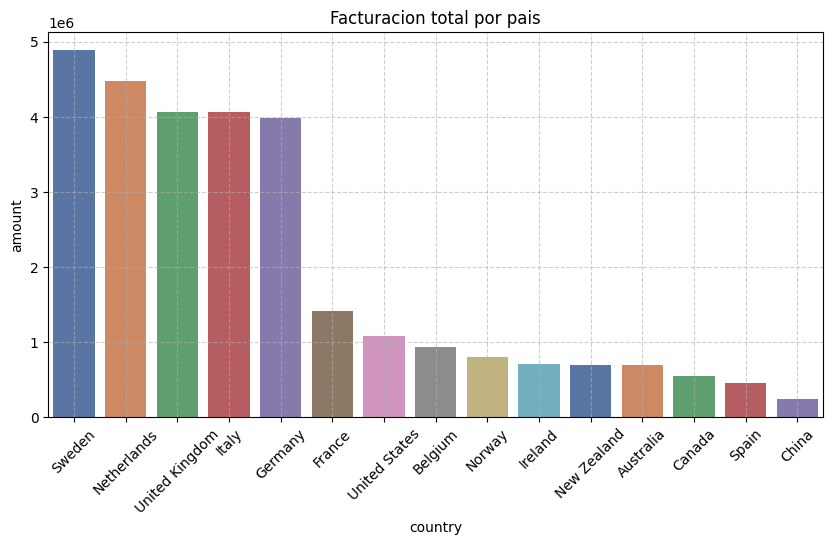

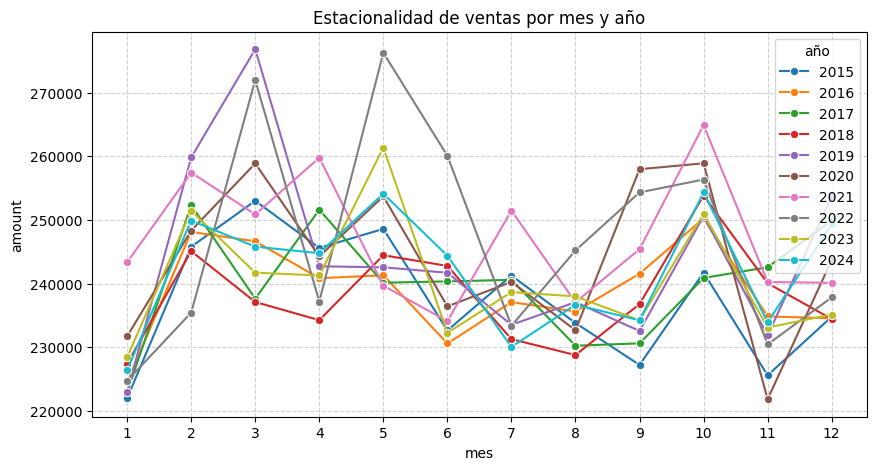

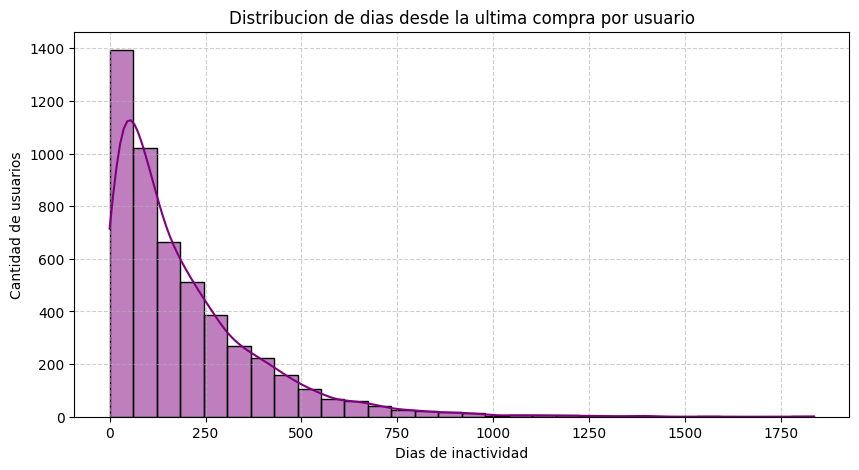

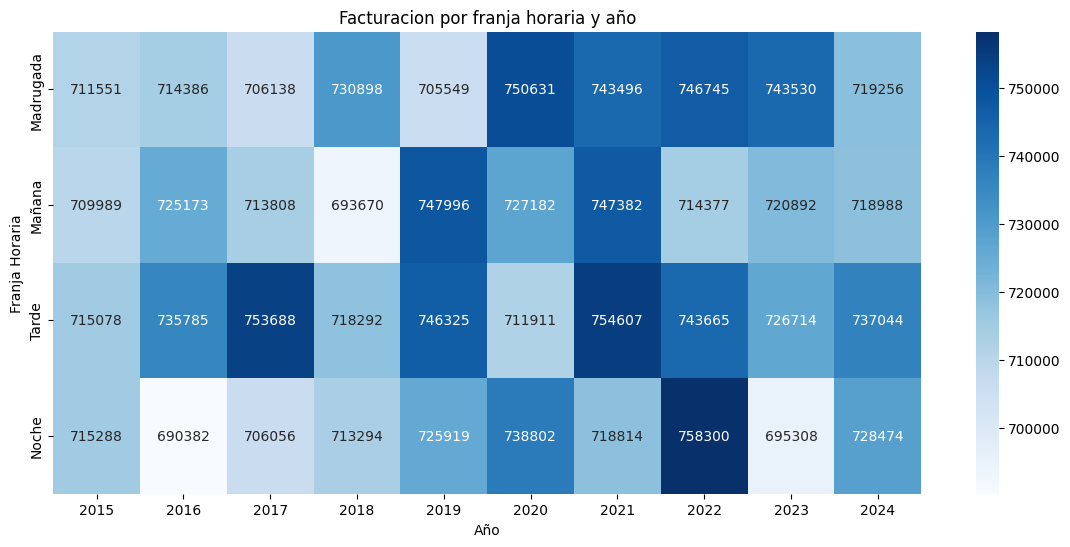

In [33]:
def dependencia_paises(df_tra, df_com):

  df_t = df_tra[df_tra["declined"] == 0].copy()

  df_join = pd.merge(df_t, df_com, left_on="business_id", right_on="company_id", how="inner")

  df_pais = df_join.groupby("country")["amount"].sum().reset_index()
  df_pais = df_pais.sort_values("amount", ascending=False)

  total_facturacion = df_pais["amount"].sum()
  df_pais["porcentaje"] = (df_pais["amount"] / total_facturacion) * 100
  df_pais["porcentaje_acumulado"] = df_pais["porcentaje"].cumsum()

  fig = plt.figure(figsize=(10, 5))
  sns.barplot(data=df_pais, x="country", y="amount", hue="country", palette="deep", legend=False)
  plt.title("Facturacion total por pais")
  plt.xticks(rotation=45)
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.close(fig)

  return df_pais, fig

def estacionalidad_ventas(df):

  df_t = df[df["declined"] == 0].copy()
  df_t["timestamp"] = pd.to_datetime(df_t["timestamp"], errors="coerce")
  df_t["año"] = df_t["timestamp"].dt.year
  df_t["mes"] = df_t["timestamp"].dt.month

  ventas_mes = df_t.groupby(["año", "mes"])["amount"].sum().reset_index()

  tabla_pivot = pd.pivot_table(ventas_mes, values="amount", index="mes", columns="año", fill_value=0)

  fig = plt.figure(figsize=(10, 5))
  sns.lineplot(data=ventas_mes, x="mes", y="amount", hue="año", marker="o", palette="tab10")
  plt.title("Estacionalidad de ventas por mes y año")
  plt.xticks(range(1, 13))
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.close(fig)

  return tabla_pivot, fig

def usuarios_inactivos(df):

  df_t = df[df["declined"] == 0].copy()
  df_t["timestamp"] = pd.to_datetime(df_t["timestamp"], errors="coerce")

  ultima_fecha = df_t["timestamp"].max()

  df_ultima_compra = df_t.groupby("user_id")["timestamp"].max().reset_index()
  df_ultima_compra["dias_inactivo"] = (ultima_fecha - df_ultima_compra["timestamp"]).dt.days

  fig = plt.figure(figsize=(10, 5))
  sns.histplot(data=df_ultima_compra, x="dias_inactivo", bins=30, kde=True, color="purple")
  plt.title("Distribucion de dias desde la ultima compra por usuario")
  plt.xlabel("Dias de inactividad")
  plt.ylabel("Cantidad de usuarios")
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.close(fig)

  return df_ultima_compra, fig

def asignar_franja(hora):

  if 6 <= hora < 12:
      return "Mañana"
  elif 12 <= hora < 18:
      return "Tarde"
  elif 18 <= hora < 24:
      return "Noche"
  else:
      return "Madrugada"

def patrones_horarios(df):

  df_t = df[df["declined"] == 0].copy()
  df_t["timestamp"] = pd.to_datetime(df_t["timestamp"], errors="coerce")
  df_t["año"] = df_t["timestamp"].dt.year
  df_t["hora"] = df_t["timestamp"].dt.hour

  df_t["franja_horaria"] = df_t["hora"].apply(asignar_franja)

  tabla_cruzada = pd.crosstab(index=df_t["franja_horaria"], columns=df_t["año"], values=df_t["amount"], aggfunc="sum")

  orden = ["Madrugada", "Mañana", "Tarde", "Noche"]
  tabla_cruzada = tabla_cruzada.reindex(orden)

  fig = plt.figure(figsize=(14, 6))
  sns.heatmap(tabla_cruzada, annot=True, fmt=".0f", cmap="Blues", annot_kws={"size": 10})
  plt.title("Facturacion por franja horaria y año")
  plt.ylabel("Franja Horaria")
  plt.xlabel("Año")
  plt.close(fig)

  return tabla_cruzada, fig

def main_analisis(df_tra, df_com):

  df_paises, fig_paises = dependencia_paises(df_tra, df_com)
  df_pivot, fig_estacionalidad = estacionalidad_ventas(df_tra)
  df_inactivos, fig_inactivos = usuarios_inactivos(df_tra)
  df_cruzada, fig_horarios = patrones_horarios(df_tra)

  display(fig_paises)
  display(fig_estacionalidad)
  display(fig_inactivos)
  display(fig_horarios)

main_analisis(transactions, companies)



Analisis:

---


Si unos pocos paises concentran un porcentaje acumulado muy alto, existe un riesgo de dependencia en caso de crisis en ese mercado.

Picos o caidas que se repiten sistematicamente en los mismos meses de distintos años indican estacionalidad clara.

Un volumen alto en el lado derecho del histograma revela una base grande de usuarios inactivos que requieren campañas de reactivacion.

El heatmap permite ver visualmente la concentracion de facturacion. Tonos mas oscuros indican donde el negocio genera mayor valor historico.

#Nivel 2

Ejercicio 1: Análisis de productos y captación de usuarios

Algorimto:
- Identificar la primera compra de cada usuario para etiquetarlo como nuevo, cruzar las transacciones con la tabla de productos y calcular los ingresos totales y la cantidad de nuevos usuarios por cada producto.

- Clasificar cada producto en categorías (Captador, Recurrente, Emergente o Estancado) comparando sus resultados con la media general, y representar esta relación en un gráfico de dispersión.


/tmp/ipykernel_1068/1894614474.py:11: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`




Rendimiento y tipología de productos


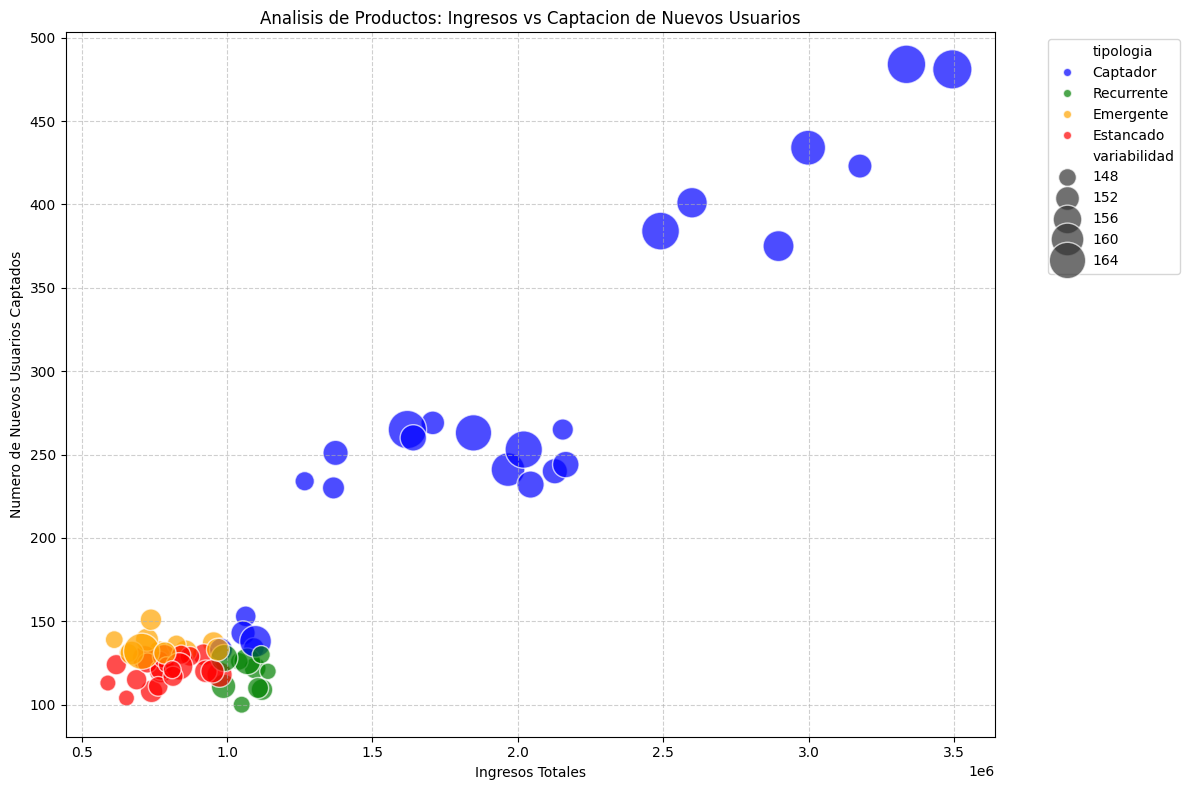

In [34]:
def analisis_productos_captacion(df_tra, df_prod):

  df_t = df_tra[df_tra["declined"] == 0].copy()
  df_t["timestamp"] = pd.to_datetime(df_t["timestamp"], errors="coerce")
  df_t = df_t.sort_values("timestamp")

  primeras_compras = df_t.drop_duplicates(subset=["user_id"], keep="first")[["id"]]
  primeras_compras["es_nou_usuari"] = True

  df_t = pd.merge(df_t, primeras_compras, on="id", how="left")
  df_t["es_nou_usuari"] = df_t["es_nou_usuari"].fillna(False)
  df_t["product_id"] = df_t["product_ids"].astype(str).str.split(",")
  df_t = df_t.explode("product_id")
  df_t["product_id"] = pd.to_numeric(df_t["product_id"].str.strip(), errors="coerce")
  df_t = df_t.dropna(subset=["product_id"])

  df_p = df_prod.rename(columns={"id": "product_id"})

  df_join = pd.merge(df_t, df_p, on="product_id", how="inner")
  agrupado = df_join.groupby("product_name").agg(ingresos_totales=("amount", "sum"),variabilidad=("amount", "std"), nuevos_usuarios=("es_nou_usuari", "sum"),total_compradores=("user_id", "nunique")).reset_index()
  agrupado["variabilidad"] = agrupado["variabilidad"].fillna(0)
  agrupado["pct_nuevos"] = (agrupado["nuevos_usuarios"] / agrupado["total_compradores"]) * 100

  mediana_ingresos = agrupado["ingresos_totales"].median()
  mediana_nuevos = agrupado["nuevos_usuarios"].median()

  def clasificar_producto(row):

      if row["ingresos_totales"] >= mediana_ingresos and row["nuevos_usuarios"] >= mediana_nuevos:
          return "Captador"
      elif row["ingresos_totales"] >= mediana_ingresos and row["nuevos_usuarios"] < mediana_nuevos:
          return "Recurrente"
      elif row["ingresos_totales"] < mediana_ingresos and row["nuevos_usuarios"] >= mediana_nuevos:
          return "Emergente"
      else:
          return "Estancado"

  agrupado["tipologia"] = agrupado.apply(clasificar_producto, axis=1)

  fig_scatter = plt.figure(figsize=(12, 8))
  sns.scatterplot(data=agrupado,x="ingresos_totales",y="nuevos_usuarios",size="variabilidad",hue="tipologia",sizes=(50, 800),alpha=0.7,palette={"Captador": "blue", "Recurrente": "green", "Emergente": "orange", "Estancado": "red"} )

  plt.title("Analisis de Productos: Ingresos vs Captacion de Nuevos Usuarios")
  plt.xlabel("Ingresos Totales")
  plt.ylabel("Numero de Nuevos Usuarios Captados")
  plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.tight_layout()
  plt.close(fig_scatter)

  return agrupado, fig_scatter

def ejecutar_analisis_productos(df_tra, df_prod):

  df_metricas, fig_analisis = analisis_productos_captacion(df_tra, df_prod)

  print("\nRendimiento y tipología de productos")
  display(fig_analisis)

ejecutar_analisis_productos(transactions, productos)


Ejercicio 2: Análisis geográfico compañero-usuario y oportunidades de expansión

Algoritmo:
 -Pregunta 1: Comparar el país del comprador con el de la compañía para determinar si la compra es local, y calcular el porcentaje global de dinero y transacciones que se mueven de forma local frente a internacional.
- Pregunta 2: Agrupar las compras por el país del usuario para extraer el importe total que gastan y calcular qué porcentaje destinan a compañías locales o extranjeras.
- Pregunta 3: Agrupar las ventas por el país de la compañía para calcular cuánto dinero facturan en total y extraer qué porcentaje proviene de clientes locales o extranjeros.
- Pregunta 4: Visualizar en gráficos de barras la proporción de consumo local de cada país y comparar el dinero demandado por los usuarios frente al ofertado por las empresas para identificar dónde abrir nuevos negocios.


--- ANÁLISIS GLOBAL ---


,compra_local,pct_transacciones,facturacion_total,pct_facturacion
0,False,88.128582,25574073.22,88.109341
1,True,11.871418,3451309.19,11.890659



--- ANÁLISIS POR PAÍS DEL USUARIO (Demanda) ---


compra_local,user_country,False,True,Total_Comprado,pct_local,pct_extranjero
4,Netherlands,2133424.87,518415.63,2651840.50,19.549276,80.450724
2,Germany,2106763.47,444114.60,2550878.07,17.410264,82.589736
3,Italy,2145026.84,440575.65,2585602.49,17.039574,82.960426
0,Canada,2395532.85,254806.44,2650339.29,9.614106,90.385894
1,France,2314074.51,153765.65,2467840.16,6.230778,93.769222



--- ANÁLISIS POR PAÍS DE COMPAÑÍA (Oferta) ---


compra_local,company_country,False,True,Facturacion_Total,pct_usuarios_locales,pct_usuarios_extranjeros
0,Australia,687532.20,0.00,687532.20,0.000000,100.000000
1,Belgium,937789.26,0.00,937789.26,0.000000,100.000000
3,China,235421.76,0.00,235421.76,0.000000,100.000000
4,France,1252902.50,153765.65,1406668.15,10.931196,89.068804
2,Canada,297261.09,254806.44,552067.53,46.154941,53.845059



--- VISUALIZACIÓN ESTRATÉGICA ---


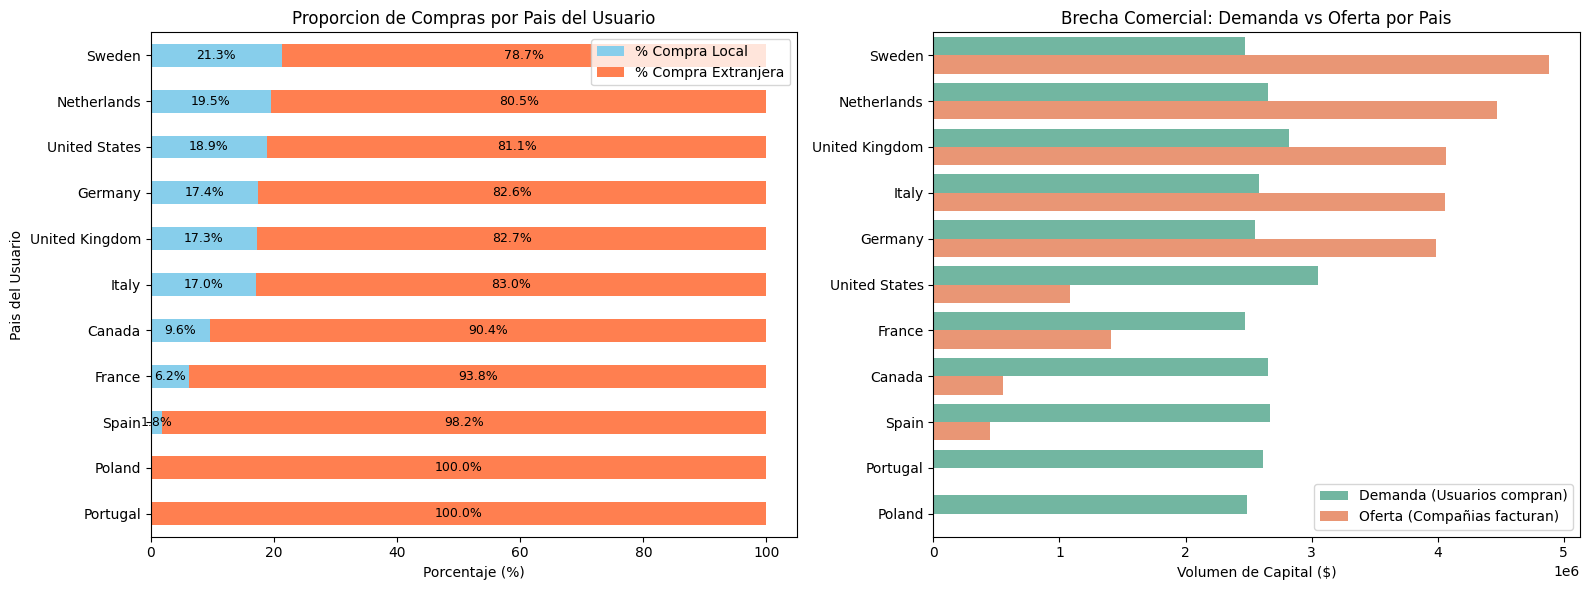

In [35]:
def analisis_geografico_expansion(df_tra, df_com, df_usa, df_eu):

  df_users = pd.concat([df_usa, df_eu], ignore_index=True)
  df_users = df_users[["id", "country"]].rename(columns={"id": "user_id", "country": "user_country"})

  df_country = df_com[["company_id", "country"]].rename(columns={"country": "company_country"})

  df_declined = df_tra[df_tra["declined"] == 0].copy()

  df_join = pd.merge(df_declined, df_country, left_on="business_id", right_on="company_id", how="inner")
  df_join = pd.merge(df_join, df_users, on="user_id", how="inner")

  df_join["compra_local"] = df_join["user_country"] == df_join["company_country"]

  global_tx = df_join["compra_local"].value_counts(normalize=True).reset_index()
  global_tx["proportion"] = global_tx["proportion"] * 100

  global_rev = df_join.groupby("compra_local")["amount"].sum().reset_index()
  global_rev["porcentaje"] = (global_rev["amount"] / global_rev["amount"].sum()) * 100

  resumen_global = pd.merge(global_tx, global_rev, on="compra_local")
  resumen_global.columns = ["compra_local", "pct_transacciones", "facturacion_total", "pct_facturacion"]

  user_stats = df_join.groupby(["user_country", "compra_local"]).agg(importe_total=("amount", "sum")).reset_index()

  user_piv = user_stats.pivot_table(index="user_country", columns="compra_local", values="importe_total", fill_value=0)
  user_piv["Total_Comprado"] = user_piv.get(True, 0) + user_piv.get(False, 0)
  user_piv["pct_local"] = (user_piv.get(True, 0) / user_piv["Total_Comprado"]) * 100
  user_piv["pct_extranjero"] = (user_piv.get(False, 0) / user_piv["Total_Comprado"]) * 100
  user_piv = user_piv.reset_index()

  comp_stats = df_join.groupby(["company_country", "compra_local"]).agg(facturacion=("amount", "sum")).reset_index()

  comp_piv = comp_stats.pivot_table(index="company_country", columns="compra_local", values="facturacion", fill_value=0)
  comp_piv["Facturacion_Total"] = comp_piv.get(True, 0) + comp_piv.get(False, 0)
  comp_piv["pct_usuarios_locales"] = (comp_piv.get(True, 0) / comp_piv["Facturacion_Total"]) * 100
  comp_piv["pct_usuarios_extranjeros"] = (comp_piv.get(False, 0) / comp_piv["Facturacion_Total"]) * 100
  comp_piv = comp_piv.reset_index()

  fig, axes = plt.subplots(1, 2, figsize=(16, 6))


  datos_plot_1 = user_piv.set_index("user_country")[["pct_local", "pct_extranjero"]].sort_values("pct_extranjero", ascending=False)
  datos_plot_1.plot(kind="barh", stacked=True, color=["skyblue", "coral"], ax=axes[0])

  for c in axes[0].containers:

        etiquetas = [f"{v.get_width():.1f}%" if v.get_width() > 0 else "" for v in c]
        axes[0].bar_label(c, labels=etiquetas, label_type="center", fontsize=9)

  axes[0].set_title("Proporcion de Compras por Pais del Usuario")
  axes[0].set_xlabel("Porcentaje (%)")
  axes[0].set_ylabel("Pais del Usuario")
  axes[0].legend(["% Compra Local", "% Compra Extranjera"])

  user_demanda = user_piv[["user_country", "Total_Comprado"]].rename(columns={"user_country": "pais", "Total_Comprado": "importe"})
  user_demanda["tipo"] = "Demanda (Usuarios compran)"

  comp_oferta = comp_piv[["company_country", "Facturacion_Total"]].rename(columns={"company_country": "pais", "Facturacion_Total": "importe"})
  comp_oferta["tipo"] = "Oferta (Compañias facturan)"

  df_brecha = pd.concat([user_demanda, comp_oferta], ignore_index=True)
  df_brecha = df_brecha[df_brecha["pais"].isin(user_demanda["pais"])]

  orden_paises = df_brecha.groupby("pais")["importe"].sum().sort_values(ascending=False).index
  sns.barplot(data=df_brecha, x="importe", y="pais", hue="tipo", ax=axes[1], palette="Set2", order=orden_paises)
  axes[1].set_title("Brecha Comercial: Demanda vs Oferta por Pais")
  axes[1].set_xlabel("Volumen de Capital ($)")
  axes[1].set_ylabel("")
  axes[1].legend(title="")

  plt.tight_layout()
  plt.close(fig)

  return resumen_global, user_piv, comp_piv, fig

def ejecutar_ejercicio_geo(df_tra, df_com, df_usa, df_eu):

  res_global, res_usuarios, res_compañias, fig_geo = analisis_geografico_expansion(df_tra, df_com, df_usa, df_eu)

  print("\n--- ANÁLISIS GLOBAL ---")
  display(res_global)

  print("\n--- ANÁLISIS POR PAÍS DEL USUARIO (Demanda) ---")
  display(res_usuarios.head().sort_values("pct_local", ascending=False))

  print("\n--- ANÁLISIS POR PAÍS DE COMPAÑÍA (Oferta) ---")
  display(res_compañias.head().sort_values("pct_usuarios_locales", ascending=True))

  print("\n--- VISUALIZACIÓN ESTRATÉGICA ---")
  display(fig_geo)

ejecutar_ejercicio_geo(transactions, companies, EUA_users, EU_users)


Análisis

---

Los países con mayor volumen de ventas a través de empresas locales fueron Suecia, los Países Bajos, Estados Unidos, Alemania y el Reino Unido, con una diferencia porcentual de 4,3 puntos.

Asimismo, países como Canadá y España presentan un mercado con una gran demanda; sin embargo, una parte reducida del comercio es local, menos del 10 %. Además, existen otros países donde el comercio local es inexistente, a pesar de que la demanda es similar a la de aquellos países donde sí existe dicho comercio.

No hay un único país que domine el negocio; no obstante, existe un predominio regional de países europeos que concentran la mayor parte del comercio.

Establecer empresas locales beneficiaría a los países con una demanda elevada que dependen, en gran medida o totalmente, del comercio exterior, ya que esto reduce la fricción y aumenta la conversión de los usuarios.

#Nivel 3

Ejercicio 1: Mini-dashboard departamental

Algoritmo:
 - Preparación: Separar los productos de las transacciones múltiples, cruzar la información con el catálogo de productos, aislar las ventas aprobadas y crear un lienzo unificado para cuatro gráficos.
- Gráfico 1: Agrupar la facturación de las compras aprobadas por mes y año, trazando una línea temporal para visualizar la evolución de los ingresos mostrando un marcador por año en el eje para mantener la legibilidad.
- Gráfico 2: Calcular el dinero total generado por cada marca y extraer las cinco principales para representarlas en un gráfico de barras horizontales.
- Gráfico 3: Extraer la hora de cada compra y sumar los importes por cada franja horaria, utilizando un gráfico de barras para identificar las horas pico de ventas durante el día.
- Gráfico 4: Contabilizar el estado de todas las transacciones, aprobadas frente a rechazadas y graficar la proporción en un diagrama circular para monitorizar la tasa de rechazo del negocio.

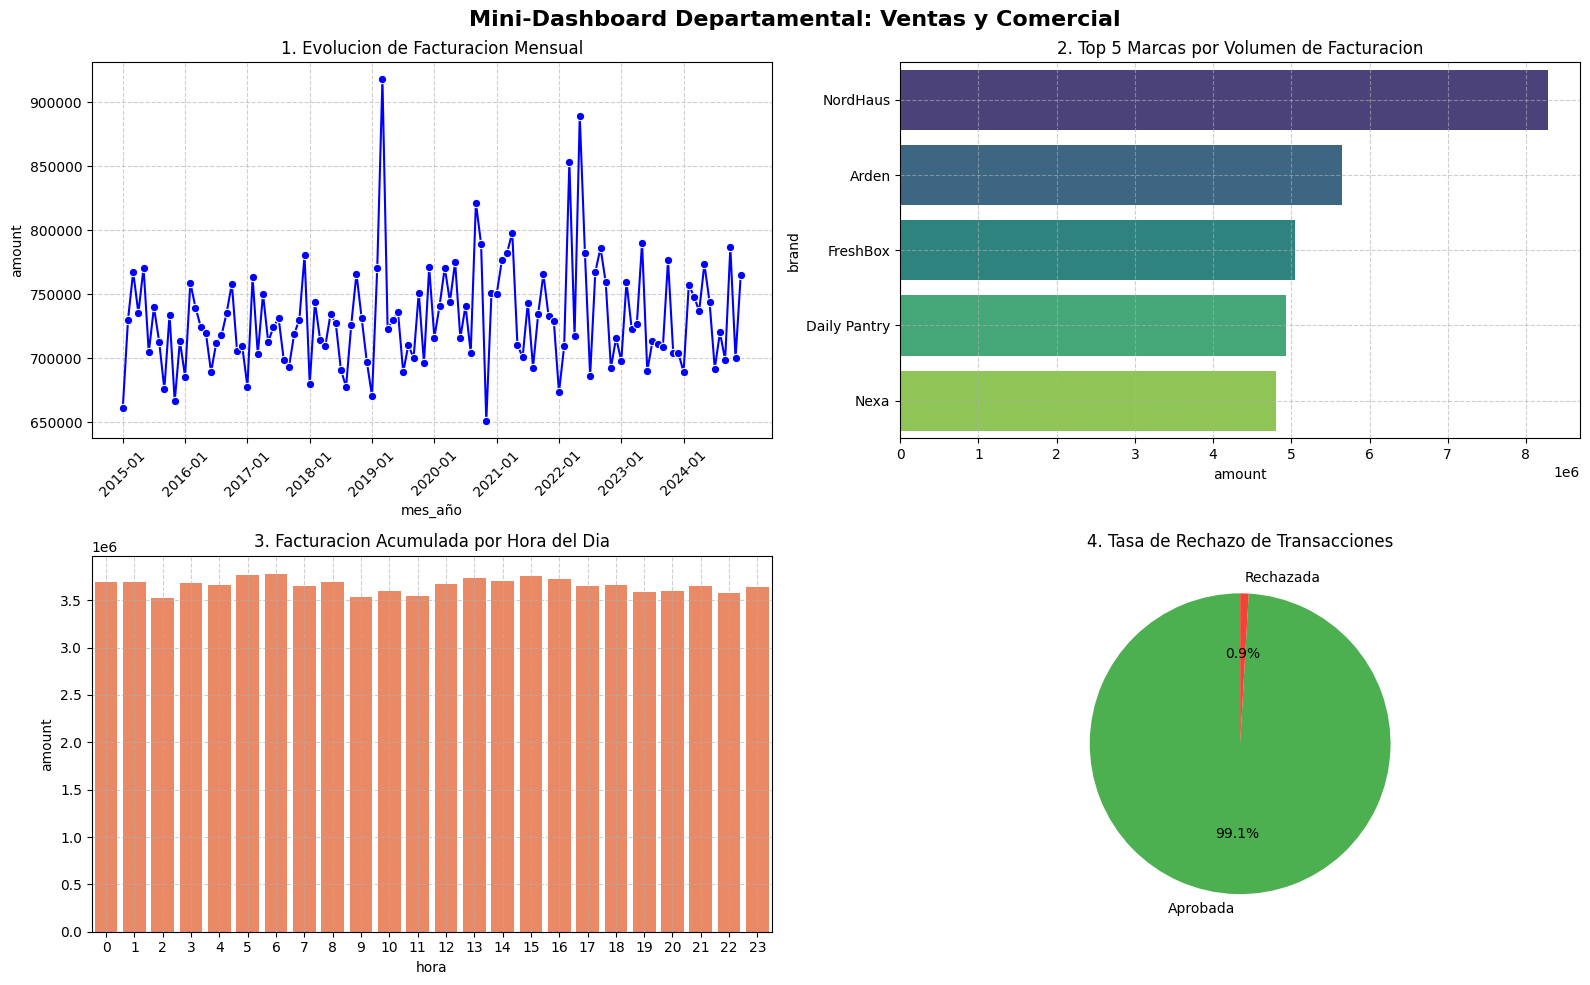

In [36]:
def dashboard_comercial(df_tra, df_prod):

  df_t = df_tra.copy()
  df_t["timestamp"] = pd.to_datetime(df_t["timestamp"], errors="coerce")

  df_t["product_id"] = df_t["product_ids"].astype(str).str.split(",")
  df_ex = df_t.explode("product_id")
  df_ex["product_id"] = pd.to_numeric(df_ex["product_id"].str.strip(), errors="coerce")
  df_ex = df_ex.dropna(subset=["product_id"])

  df_p = df_prod.rename(columns={"id": "product_id"})
  df_join = pd.merge(df_ex, df_p, on="product_id", how="inner")

  df_aprobadas = df_join[df_join["declined"] == 0].copy()

  fig, ejes = plt.subplots(2, 2, figsize=(16, 10))
  fig.suptitle("Mini-Dashboard Departamental: Ventas y Comercial", fontsize=16, fontweight="bold")

  df_aprobadas["mes_año"] = df_aprobadas["timestamp"].dt.to_period("M").astype(str)
  ventas_mes = df_aprobadas.groupby("mes_año")["amount"].sum().reset_index()
  ventas_mes = ventas_mes.sort_values("mes_año")

  sns.lineplot(data=ventas_mes, x="mes_año", y="amount", marker="o", color="blue", ax=ejes[0, 0])
  ejes[0, 0].set_title("1. Evolucion de Facturacion Mensual")

  ticks_atuais = ejes[0, 0].get_xticks()
  ejes[0, 0].set_xticks(ticks_atuais[::12])

  ejes[0, 0].tick_params(axis='x', rotation=45)
  ejes[0, 0].grid(True, linestyle="--", alpha=0.6)

  top_marcas = df_aprobadas.groupby("brand")["amount"].sum().reset_index()
  top_marcas = top_marcas.sort_values("amount", ascending=False).head(5)

  sns.barplot(data=top_marcas, x="amount", y="brand", hue="brand", palette="viridis", ax=ejes[0, 1], legend=False)
  ejes[0, 1].set_title("2. Top 5 Marcas por Volumen de Facturacion")
  ejes[0, 1].grid(True, linestyle="--", alpha=0.6)

  df_aprobadas["hora"] = df_aprobadas["timestamp"].dt.hour
  ventas_hora = df_aprobadas.groupby("hora")["amount"].sum().reset_index()

  sns.barplot(data=ventas_hora, x="hora", y="amount", color="coral", ax=ejes[1, 0])
  ejes[1, 0].set_title("3. Facturacion Acumulada por Hora del Dia")
  ejes[1, 0].grid(True, linestyle="--", alpha=0.6)

  estado_tx = df_join["declined"].value_counts().reset_index()
  estado_tx["declined"] = estado_tx["declined"].map({0: "Aprobada", 1: "Rechazada"})

  ejes[1, 1].pie(estado_tx["count"], labels=estado_tx["declined"], autopct='%1.1f%%', colors=["#4CAF50", "#F44336"], startangle=90)
  ejes[1, 1].set_title("4. Tasa de Rechazo de Transacciones")

  plt.tight_layout()
  plt.close(fig)

  return fig

def main_dashboard(df_tra, df_prod):

  figura_dash = dashboard_comercial(df_tra, df_prod)
  display(figura_dash)

main_dashboard(transactions, productos)

Ejercicio 2: Informe ejecutivo

Versión Sin IA
1. Resumen general
Hemos analizado los datos de facturación mensual, las ventas por marca, los horarios de compra y los pagos rechazados. El objetivo de este análisis es ayudar al equipo Comercial a entender cómo estamos vendiendo y detectar puntos débiles para mejorar los ingresos.

2. Hallazgos clave
Las ventas mensuales tienen picos muy fuertes en ciertos meses, pero no son estables durante todo el año.
Un grupo muy pequeño de marcas en el Top 5 genera la gran mayoría de todo el dinero que ingresamos.
Los clientes tienen horas muy claras para comprar, dejando el resto del día casi sin ventas.

3. Riesgos detectados
Dependencia de marcas: Si alguna de nuestras marcas del Top 5 deja de vender o se va, el negocio perdería casi todos sus ingresos de golpe.
Pérdida de dinero por rechazos: Tenemos un porcentaje de transacciones rechazadas que significa dinero que los clientes querían gastar y no pudieron.

4. Oportunidades
Hay países como Polonia y Portugal donde la gente gasta mucho dinero, pero no tenemos ninguna empresa vendedora allí. Podemos buscar vendedores en esos lugares.
Se pueden lanzar descuentos especiales en las horas del día donde casi nadie compra para levantar las ventas en esos momentos.

5. Recomendaciones
Buscar y añadir nuevas marcas al catálogo para no depender solo de las cinco más grandes.
Revisar con el equipo técnico por qué fallan las tarjetas para recuperar esas ventas perdidas.
Implementar estrategias comerciales orientadas a la fidelización y previsibilidad del volumen de ventas.

Versión con apoyo de IA
1. Resumen general
El presente informe evalúa el rendimiento comercial del ecosistema transaccional, analizando la evolución del revenue, la concentración del portfolio de marcas, la distribución horaria de la demanda y el embudo de conversión. El objetivo es proporcionar insights estratégicos a la Dirección de Ventas para optimizar la rentabilidad.

2. Hallazgos clave
Volatilidad en la facturación: Se observa una fuerte estacionalidad en el volumen de ventas, con picos de facturación seguidos de caídas pronunciadas, lo que dificulta el pronóstico de caja (forecasting).
Efecto Pareto en el portfolio: El Top 5 de marcas aglutina la gran mayoría del Market Share interno, indicando una altísima concentración del volumen de negocio.
Patrones de consumo hiper-segmentados: El flujo transaccional se concentra fuertemente en franjas horarias específicas, generando una infrautilización de la plataforma en las horas valle.

3. Riesgos detectados
Riesgo de concentración de cartera: Existe una dependencia crítica del rendimiento de un grupo muy reducido de marcas; la pérdida de uno solo de estos key partners comprometería severamente el top-line revenue.
Fricción en el checkout: La tasa de rechazo de transacciones representa una pérdida directa de conversión (churn involuntario), impactando negativamente en el Coste de Adquisición de Clientes (CAC).

4. Oportunidades
Expansión Cross-Border: Los datos previos muestran bolsas de demanda insatisfecha (Polonia, Portugal, España). Incorporar merchants (vendedores) locales en estos mercados reduciría la fricción de compra internacional y dispararía el volumen bruto de mercancías (GMV).
Optimización de franjas valle: Diseñar campañas promocionales temporales (flash sales) sincronizadas con las horas de menor tráfico para suavizar la curva de demanda.

5. Recomendaciones
Diversificar activamente el partnership de marcas para diluir el riesgo operativo y equilibrar el peso de la facturación.
Auditar la pasarela de pagos (payment gateway) para diagnosticar los rechazos y aplicar planes de recuperación de carritos abandonados.
Implementar estrategias comerciales orientadas a la fidelización y previsibilidad del volumen de ventas.